# Predictive Maintenance of Aircraft Engines: Remaining Useful Life Estimation Using Regression Models

## 1. Project Introduction
Aircraft engines operate under complex conditions and experience
gradual performance degradation over time. Predicting when an
engine may require maintenance is important for improving
operational safety and reducing unexpected failures.

This project focuses on developing a machine learning-based
predictive maintenance system that estimates the Remaining Useful
Life (RUL) of aircraft engines using historical sensor readings
and operational data from the NASA C-MAPSS dataset.

Regression algorithms are implemented and compared to identify
a suitable model for predicting the remaining operating cycles
of aircraft engines.

### 1.1 Problem Statement
Aircraft engines generate sensor data during their operation.
Identifying engine degradation and estimating the remaining
useful life from these readings is a challenging task.

The problem addressed in this project is to develop a regression-
based machine learning model that can predict the Remaining
Useful Life (RUL) of an aircraft engine using its operational
settings and sensor measurements.

The objective is to estimate the number of remaining operating
cycles before an engine reaches its end of useful life.

### 1.2 Project Objectives
The main objectives of this project are:

1. To understand and analyse the NASA C-MAPSS aircraft engine dataset.
2. To perform exploratory data analysis on sensor readings and
   operating conditions.
3. To clean and preprocess the dataset for machine learning.
4. To calculate Remaining Useful Life (RUL) as the prediction target.
5. To implement three regression algorithms:
   - Linear Regression
   - Random Forest Regressor
   - Gradient Boosting Regressor
6. To compare model performance using MAE, MSE, RMSE and R² Score.
7. To select and evaluate the best-performing regression model.
8. To analyse important features influencing RUL predictions.

### 1.3 Project Scope
This project focuses on predictive maintenance of aircraft
engines using the NASA C-MAPSS FD001 dataset.

The scope includes:

- Analysing historical engine sensor measurements.
- Performing data preprocessing and feature engineering.
- Calculating and predicting Remaining Useful Life.
- Implementing and comparing three regression models.
- Evaluating model performance on unseen test engine data.
- Identifying important features influencing predictions.

The project is limited to the FD001 subset and uses simulated
engine degradation data for model development and evaluation.

## 2. Library Imports and Setup

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Model training
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Dataset splitting
from sklearn.model_selection import train_test_split

# Model saving
import joblib

# File and directory management
from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Visualization settings
sns.set_style("whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Dataset Loading

In [2]:
# Define dataset directory
data_path = Path("../data_aml/CMaps")

# Define column names
column_names = (
    ['engine_id', 'cycle'] +
    [f'op_setting_{i}' for i in range(1, 4)] +
    [f'sensor_{i}' for i in range(1, 22)]
)

# Define dataset file paths
train_file = data_path / "train_FD001.txt"
test_file = data_path / "test_FD001.txt"
rul_file = data_path / "RUL_FD001.txt"

# Check whether dataset files exist
for file in [train_file, test_file, rul_file]:
    if not file.exists():
        raise FileNotFoundError(f"Dataset file not found: {file}")

# Load training dataset
train_data = pd.read_csv(
    train_file,
    sep=r'\s+',
    header=None,
    names=column_names
)

# Load testing dataset
test_data = pd.read_csv(
    test_file,
    sep=r'\s+',
    header=None,
    names=column_names
)

# Load actual RUL values
rul_data = pd.read_csv(
    rul_file,
    sep=r'\s+',
    header=None,
    names=['RUL']
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


### 3.1 Dataset Dimensions

In [3]:
print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)
print("RUL Dataset Shape:", rul_data.shape)

Training Dataset Shape: (20631, 26)
Testing Dataset Shape: (13096, 26)
RUL Dataset Shape: (100, 1)


### 3.2 Dataset Preview

In [4]:
print("Training Dataset:")
display(train_data.head())

print("Testing Dataset:")
display(test_data.head())

print("Actual RUL Dataset:")
display(rul_data.head())

Training Dataset:


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Testing Dataset:


,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,21.61,553.90,2388.04,9050.17,1.3,47.20,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,21.61,554.85,2388.01,9054.42,1.3,47.50,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,21.61,554.11,2388.05,9056.96,1.3,47.50,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,21.61,554.07,2388.03,9045.29,1.3,47.28,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,21.61,554.16,2388.01,9044.55,1.3,47.31,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


Actual RUL Dataset:


,RUL
0,112
1,98
2,69
3,82
4,91


## 4. Dataset Description

### 4.1 Dataset Features

In [5]:
# Display all dataset columns
print("Total Number of Features:", len(train_data.columns))

print("\nDataset Column Names:")
print(train_data.columns.tolist())

Total Number of Features: 26

Dataset Column Names:
['engine_id', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


**Dataset Source:**

NASA Prognostics Data Repository

Dataset: NASA C-MAPSS Turbofan Engine
Degradation Simulation Dataset (FD001)

Official Source:
https://www.nasa.gov/intelligent-systems-division/
discovery-and-systems-health/pcoe/pcoe-data-set-repository/

The dataset was developed for aircraft engine
degradation and Remaining Useful Life prediction research.

Reference:
A. Saxena, K. Goebel, D. Simon and N. Eklund,
"Damage Propagation Modeling for Aircraft Engine
Run-to-Failure Simulation," 2008.

### 4.2 Dataset Information

In [57]:
print("Training Dataset Information:")
train_data.info()

Training Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 63 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   engine_id               20631 non-null  int64  
 1   cycle                   20631 non-null  int64  
 2   op_setting_1            20631 non-null  float64
 3   op_setting_2            20631 non-null  float64
 4   op_setting_3            20631 non-null  float64
 5   sensor_1                20631 non-null  float64
 6   sensor_2                20631 non-null  float64
 7   sensor_3                20631 non-null  float64
 8   sensor_4                20631 non-null  float64
 9   sensor_5                20631 non-null  float64
 10  sensor_6                20631 non-null  float64
 11  sensor_7                20631 non-null  float64
 12  sensor_8                20631 non-null  float64
 13  sensor_9                20631 non-null  float64
 14  sensor_10          

### 4.3 Statistical Summary

In [58]:
train_data.describe()

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL_raw,RUL,sensor_2_rolling_mean,sensor_2_rolling_std,sensor_3_rolling_mean,sensor_3_rolling_std,sensor_4_rolling_mean,sensor_4_rolling_std,sensor_5_rolling_mean,sensor_5_rolling_std,sensor_6_rolling_mean,sensor_6_rolling_std,sensor_7_rolling_mean,sensor_7_rolling_std,sensor_8_rolling_mean,sensor_8_rolling_std,sensor_9_rolling_mean,sensor_9_rolling_std,sensor_11_rolling_mean,sensor_11_rolling_std,sensor_12_rolling_mean,sensor_12_rolling_std,sensor_13_rolling_mean,sensor_13_rolling_std,sensor_14_rolling_mean,sensor_14_rolling_std,sensor_15_rolling_mean,sensor_15_rolling_std,sensor_16_rolling_mean,sensor_16_rolling_std,sensor_17_rolling_mean,sensor_17_rolling_std,sensor_20_rolling_mean,sensor_20_rolling_std,sensor_21_rolling_mean,sensor_21_rolling_std
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.0,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.0,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,21.609803,553.367711,2388.096652,9065.242941,1.3,47.541168,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705,216.615724,107.807862,86.829286,642.668177,0.282887,1590.371974,3.743819,1408.670908,3.772323,1.462000e+01,0.0,21.609798,0.000387,553.392492,0.379234,2388.094887,0.028255,9064.827207,3.946680,47.533241,0.095131,521.434437,0.281756,2388.094344,0.028451,8143.460137,3.016360,8.441132,0.018802,3.000000e-02,0.0,393.169949,0.885173,38.821209,0.094636,23.292606,0.056483
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,0.001389,0.885092,0.070985,22.082880,0.0,0.267087,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251,50.028600,68.880990,41.673699,0.410199,0.105588,4.864211,1.405689,8.032418,1.402446,5.329200e-15,0.0,0.000734,0.001291,0.787783,0.145381,0.064036,0.010881,20.825535,1.513374,0.244682,0.035433,0.669201,0.105403,0.064908,0.011049,18.072103,1.143912,0.032072,0.007103,3.469531e-18,0.0,1.263436,0.341989,0.152667,0.034867,0.091651,0.020669
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,21.600000,549.850000,2387.900000,9021.730000,1.3,46.850000,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200,128.000000,0.000000,0.000000,641.450000,0.000000,1573.020000,0.000000,1387.380000,0.000000,1.462000e+01,0.0,21.600000,0.000000,550.810000,0.000000,2387.920000,0.000000,9027.652000,0.000000,46.930000,0.000000,519.224000,0.000000,2387.930000,0.000000,8103.466000,0.000000,8.330300,0.000000,3.000000e-02,0.0,390.000000,0.000000,38.326000,0.000000,23.011400,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,21.610000,552.810000,2388.050000,9053.100000,1.3,47.350000,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800,185.000000,51.000000,51.000000,642.366000,0.207437,1586.869000,2.756107,1402.633000,2.784935,1.4

### 4.4 Engine Distribution

In [59]:
print("Number of Training Engines:", train_data['engine_id'].nunique())

print("Number of Testing Engines:", test_data['engine_id'].nunique())

print("\nTraining Operating Cycles:")
print(train_data.groupby('engine_id')['cycle'].max().describe())

Number of Training Engines: 100
Number of Testing Engines: 100

Training Operating Cycles:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


## 5. Exploratory Data Analysis (EDA)

### 5.1 Operating Cycle Distribution

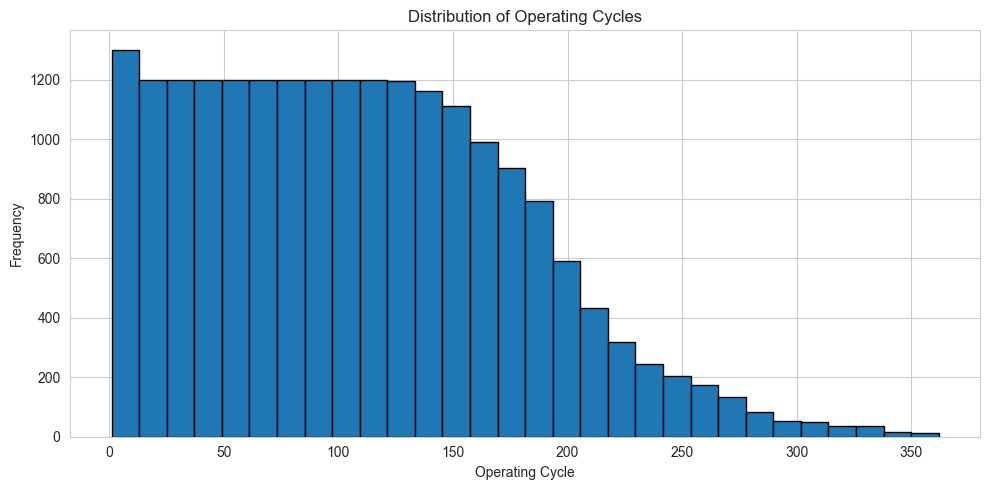

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_data['cycle'],
    bins=30,
    edgecolor='black'
)

plt.title("Distribution of Operating Cycles")
plt.xlabel("Operating Cycle")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 5.2 Engine Operating Life Distribution

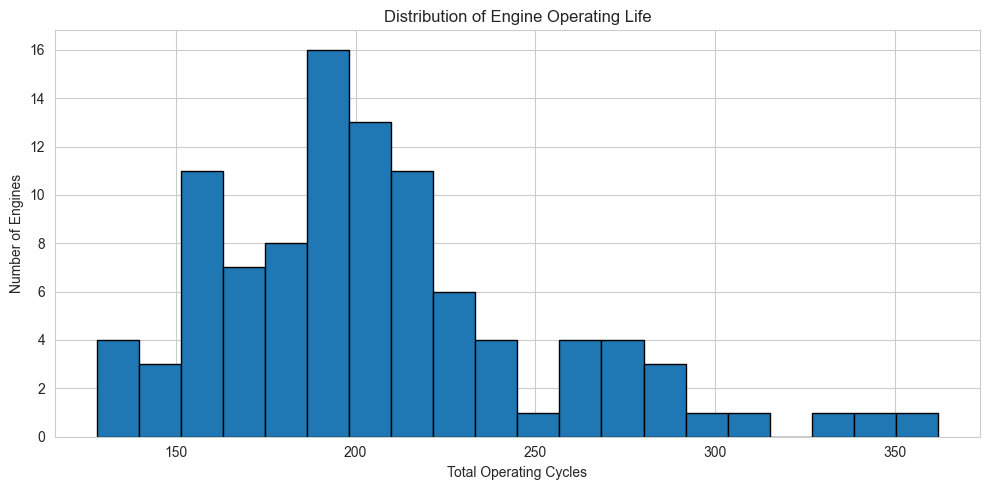

In [10]:
engine_life = train_data.groupby('engine_id')['cycle'].max()

plt.figure(figsize=(10, 5))

plt.hist(
    engine_life,
    bins=20,
    edgecolor='black'
)

plt.title("Distribution of Engine Operating Life")
plt.xlabel("Total Operating Cycles")
plt.ylabel("Number of Engines")

plt.tight_layout()
plt.show()

### 5.3 Sensor Readings Distribution

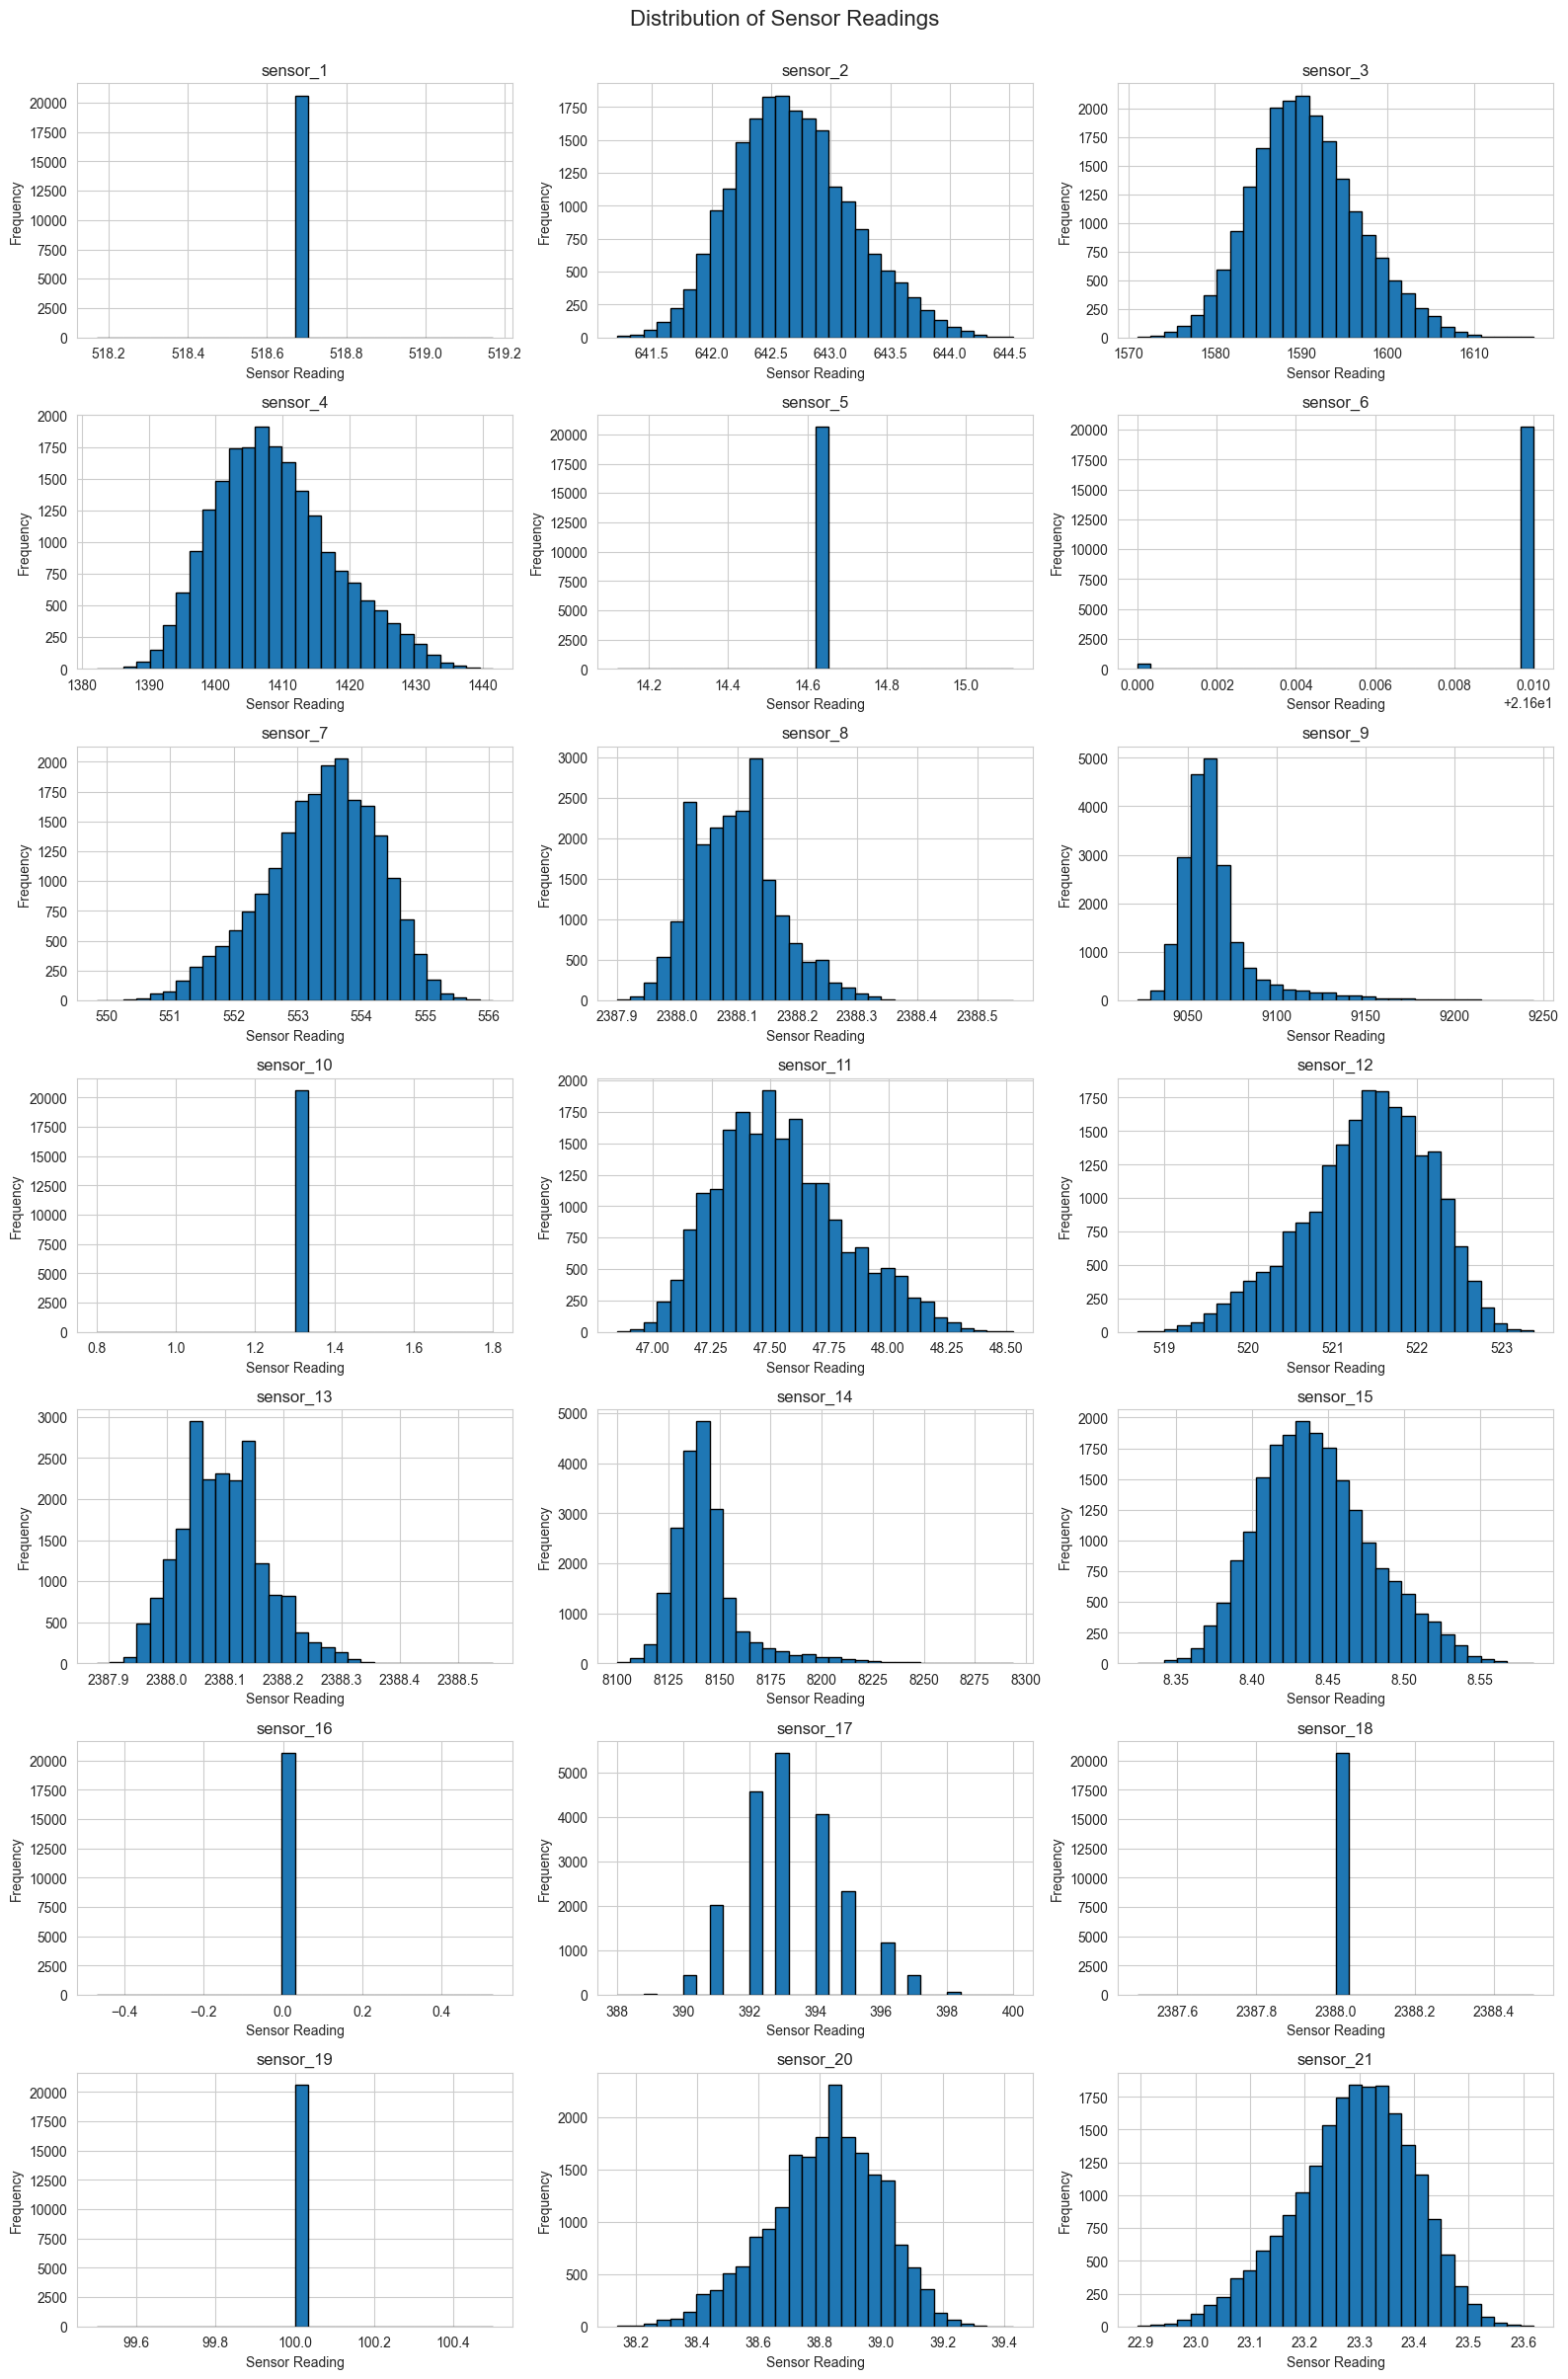

In [11]:
# Identify sensor columns
sensor_cols = [f'sensor_{i}' for i in range(1, 22)]

# Plot distributions of all 21 sensors
fig, axes = plt.subplots(7, 3, figsize=(16, 24))

for sensor, ax in zip(sensor_cols, axes.flatten()):
    ax.hist(
        train_data[sensor],
        bins=30,
        edgecolor='black'
    )

    ax.set_title(sensor)
    ax.set_xlabel("Sensor Reading")
    ax.set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Sensor Readings",
    fontsize=16,
    y=1.002
)

plt.tight_layout()
plt.show()

### 5.4 Operating Settings Distribution

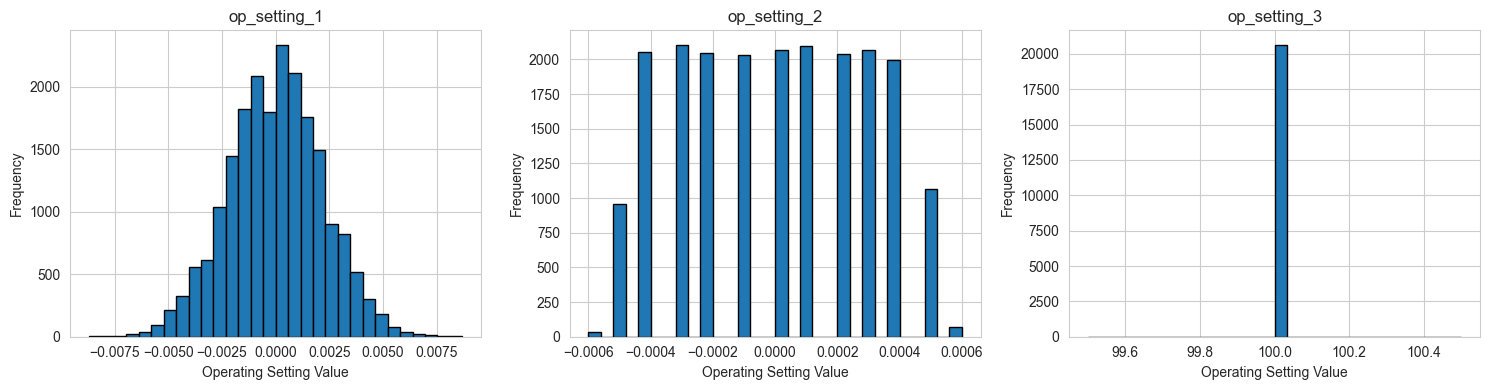

In [12]:
# Identify operating setting columns
setting_cols = [
    'op_setting_1',
    'op_setting_2',
    'op_setting_3'
]

# Visualize operating settings
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for setting, ax in zip(setting_cols, axes):
    ax.hist(
        train_data[setting],
        bins=30,
        edgecolor='black'
    )

    ax.set_title(setting)
    ax.set_xlabel("Operating Setting Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6. Data Quality Analysis

### 6.1 Missing Values Analysis

In [13]:
# Check missing values in all datasets

print("Training Dataset Missing Values:")
print(train_data.isnull().sum().sum())

print("\nTesting Dataset Missing Values:")
print(test_data.isnull().sum().sum())

print("\nRUL Dataset Missing Values:")
print(rul_data.isnull().sum().sum())

Training Dataset Missing Values:
0

Testing Dataset Missing Values:
0

RUL Dataset Missing Values:
0


### 6.2 Duplicate Records Analysis

In [14]:
# Check duplicate records

print("Training Dataset Duplicates:",
      train_data.duplicated().sum())

print("Testing Dataset Duplicates:",
      test_data.duplicated().sum())

print("RUL Dataset Duplicates:",
      rul_data.duplicated().sum())

Training Dataset Duplicates: 0
Testing Dataset Duplicates: 0
RUL Dataset Duplicates: 29


**Observation:**

The training and testing datasets contain no duplicate records.

The RUL dataset contains 29 repeated values. These repetitions
are expected because different engines can have the same
Remaining Useful Life.

Therefore, these repeated RUL values are valid labels and
should not be removed.

### 6.3 Engine Cycle Consistency Check

In [15]:
# Check duplicate engine-cycle combinations

train_duplicate_cycles = train_data.duplicated(
    subset=['engine_id', 'cycle']
).sum()

test_duplicate_cycles = test_data.duplicated(
    subset=['engine_id', 'cycle']
).sum()

print("Training Duplicate Engine-Cycle Records:",
      train_duplicate_cycles)

print("Testing Duplicate Engine-Cycle Records:",
      test_duplicate_cycles)

# Check whether cycle numbers start from 1
print("\nMinimum Training Cycle:",
      train_data.groupby('engine_id')['cycle'].min().min())

print("Minimum Testing Cycle:",
      test_data.groupby('engine_id')['cycle'].min().min())

Training Duplicate Engine-Cycle Records: 0
Testing Duplicate Engine-Cycle Records: 0

Minimum Training Cycle: 1
Minimum Testing Cycle: 1


### 6.4 Dataset Consistency Verification

In [16]:
# Verify dataset structure and values

print("Training Dataset Checks")
print("------------------------")

print("Unique Engine IDs:",
      train_data['engine_id'].nunique())

print("Total Records:",
      len(train_data))

print("Invalid Engine IDs:",
      (train_data['engine_id'] <= 0).sum())

print("Invalid Operating Cycles:",
      (train_data['cycle'] <= 0).sum())

print("\nTesting Dataset Checks")
print("----------------------")

print("Unique Engine IDs:",
      test_data['engine_id'].nunique())

print("Total Records:",
      len(test_data))

print("Invalid Engine IDs:",
      (test_data['engine_id'] <= 0).sum())

print("Invalid Operating Cycles:",
      (test_data['cycle'] <= 0).sum())

Training Dataset Checks
------------------------
Unique Engine IDs: 100
Total Records: 20631
Invalid Engine IDs: 0
Invalid Operating Cycles: 0

Testing Dataset Checks
----------------------
Unique Engine IDs: 100
Total Records: 13096
Invalid Engine IDs: 0
Invalid Operating Cycles: 0


## 7. Outlier Analysis

### 7.1 Outlier Detection Using IQR Method

In [17]:
# Calculate Q1 and Q3 for sensor readings
Q1 = train_data[sensor_cols].quantile(0.25)
Q3 = train_data[sensor_cols].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers in each sensor
outlier_counts = (
    (train_data[sensor_cols] < lower_bound) |
    (train_data[sensor_cols] > upper_bound)
).sum()

# Create outlier summary
outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_counts,
    'Outlier Percentage': (
        outlier_counts / len(train_data) * 100
    )
})

print("Outlier Analysis Summary:")
display(outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
))

Outlier Analysis Summary:


,Outlier Count,Outlier Percentage
sensor_9,1686,8.172168
sensor_14,1543,7.479036
sensor_6,406,1.967912
sensor_8,320,1.551064
sensor_11,167,0.809461
...,...,...
sensor_1,0,0.000000
sensor_10,0,0.000000
sensor_16,0,0.000000
sensor_19,0,0.000000


### 7.2 Sensor Outlier Visualization

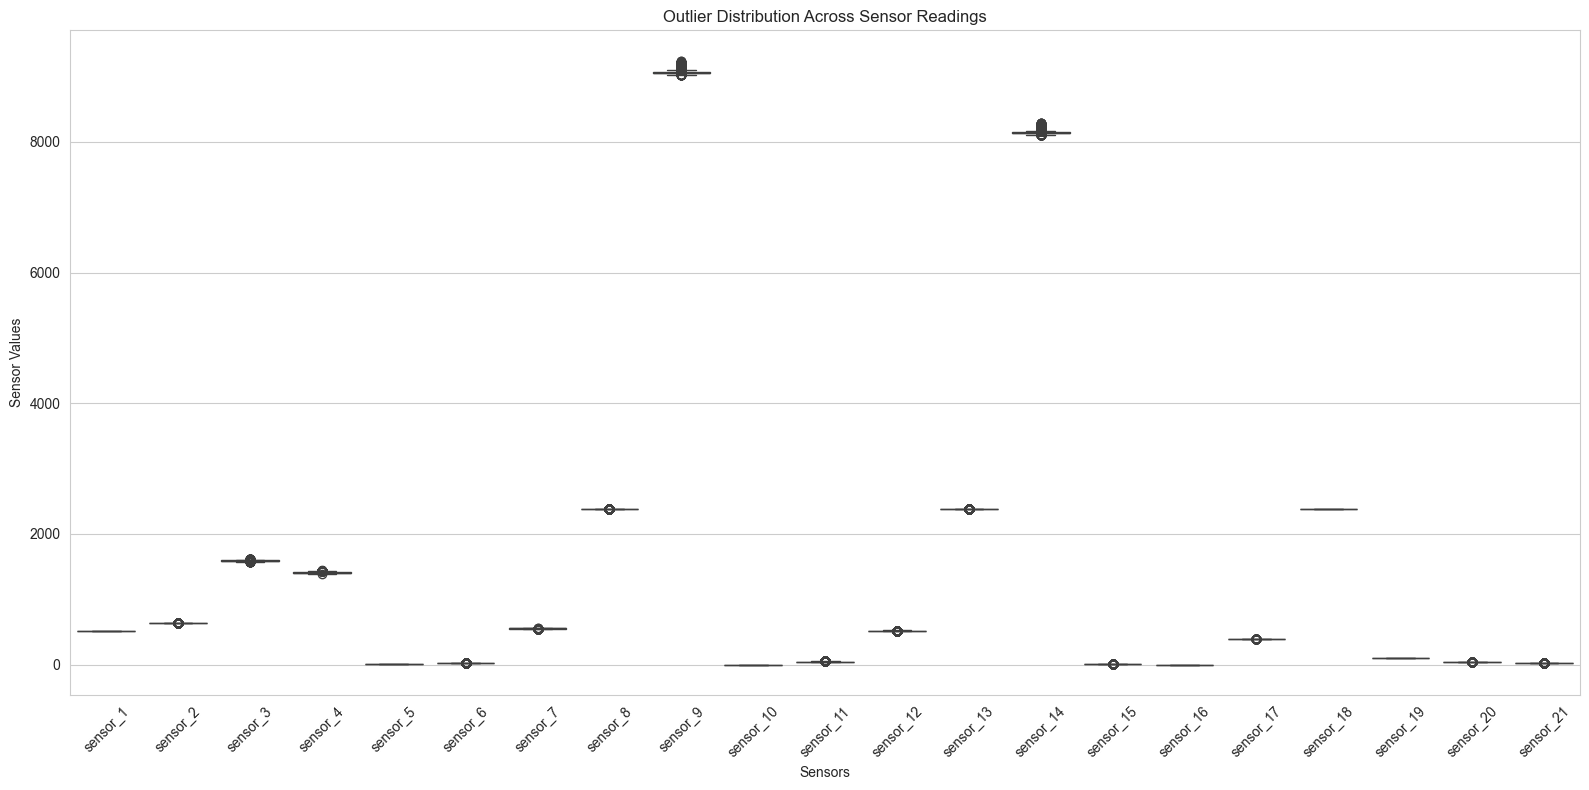

In [18]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=train_data[sensor_cols])

plt.title("Outlier Distribution Across Sensor Readings")
plt.xlabel("Sensors")
plt.ylabel("Sensor Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 7.3 Outlier Summary

In [19]:
total_outliers = outlier_counts.sum()

print("Total Sensor Outliers:", total_outliers)

print("Sensors with Outliers:",
      (outlier_counts > 0).sum())

print("Sensors without Outliers:",
      (outlier_counts == 0).sum())

print("\nOutlier Handling Decision:")
print("Outliers will be retained for further analysis.")

Total Sensor Outliers: 5406
Sensors with Outliers: 15
Sensors without Outliers: 6

Outlier Handling Decision:
Outliers will be retained for further analysis.


## 8. Remaining Useful Life (RUL) Calculation

### 8.1 Calculate Maximum Operating Cycle

In [20]:
# Calculate the maximum operating cycle for each engine

max_cycles = train_data.groupby('engine_id')['cycle'].max()

print("Maximum Operating Cycles:")
display(max_cycles.head(10))

Maximum Operating Cycles:


engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

### 8.2 Calculate Raw Remaining Useful Life

In [21]:
# Map maximum cycle to each engine
train_data['max_cycle'] = train_data['engine_id'].map(max_cycles)

# Calculate raw RUL
train_data['RUL_raw'] = (
    train_data['max_cycle'] - train_data['cycle']
)

# Display calculated RUL
display(
    train_data[
        ['engine_id', 'cycle', 'max_cycle', 'RUL_raw']
    ].head(10)
)

,engine_id,cycle,max_cycle,RUL_raw
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


### 8.3 Apply RUL Capping

In [22]:
# Define maximum RUL threshold
RUL_CAP = 125

# Apply piecewise linear RUL capping
train_data['RUL'] = train_data['RUL_raw'].clip(
    upper=RUL_CAP
)

print("RUL Capping Applied Successfully!")

print("\nRaw RUL Maximum:", train_data['RUL_raw'].max())
print("Capped RUL Maximum:", train_data['RUL'].max())

display(
    train_data[
        ['engine_id', 'cycle', 'RUL_raw', 'RUL']
    ].head(15)
)

RUL Capping Applied Successfully!

Raw RUL Maximum: 361
Capped RUL Maximum: 125


,engine_id,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


### 8.4 RUL Distribution Analysis

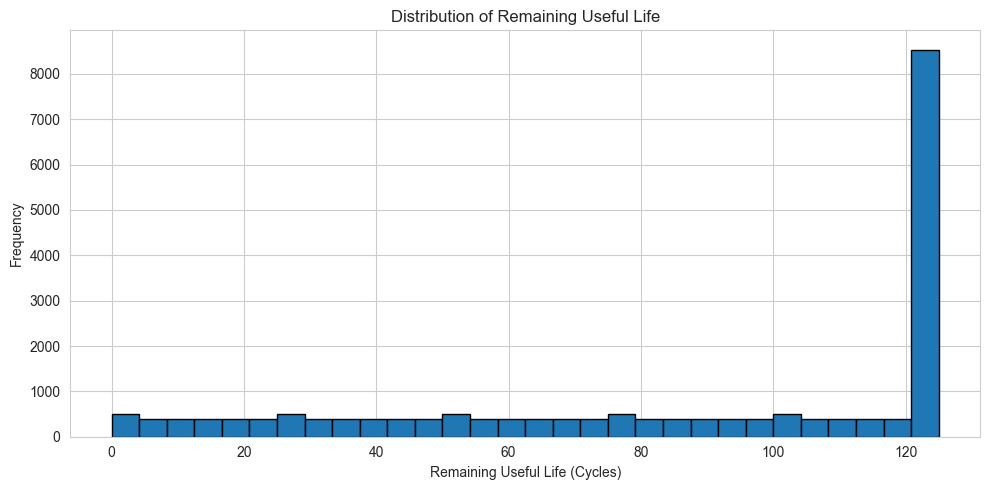

In [23]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_data['RUL'],
    bins=30,
    edgecolor='black'
)

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 8.5 RUL Statistics

In [24]:
print("RUL Statistical Summary:")
display(train_data['RUL'].describe())

print("\nNumber of Engines:",
      train_data['engine_id'].nunique())

print("Maximum RUL:", train_data['RUL'].max())
print("Minimum RUL:", train_data['RUL'].min())

RUL Statistical Summary:


count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000
Name: RUL, dtype: float64


Number of Engines: 100
Maximum RUL: 125
Minimum RUL: 0


## 9. Feature Engineering

### 9.1 Identification of Constant Sensors

In [25]:
# Calculate variance of all sensor readings
sensor_variance = train_data[sensor_cols].var()

# Identify sensors with zero variance
constant_sensors = sensor_variance[
    sensor_variance == 0
].index.tolist()

# Select sensors with varying readings
selected_sensors = [
    sensor for sensor in sensor_cols
    if sensor not in constant_sensors
]

print("Constant Sensors:", constant_sensors)

print("\nNumber of Constant Sensors:",
      len(constant_sensors))

print("\nSelected Sensors:", selected_sensors)

print("Number of Selected Sensors:",
      len(selected_sensors))

Constant Sensors: ['sensor_1', 'sensor_10', 'sensor_18', 'sensor_19']

Number of Constant Sensors: 4

Selected Sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']
Number of Selected Sensors: 17


### 9.2 Creation of Rolling Statistical Features

In [26]:
def create_rolling_features(data):

    data = data.sort_values(
        ['engine_id', 'cycle']
    ).copy()

    for sensor in selected_sensors:

        data[f'{sensor}_rolling_mean'] = (
            data.groupby('engine_id')[sensor]
            .transform(
                lambda x: x.rolling(
                    window=5,
                    min_periods=1
                ).mean()
            )
        )

        data[f'{sensor}_rolling_std'] = (
            data.groupby('engine_id')[sensor]
            .transform(
                lambda x: x.rolling(
                    window=5,
                    min_periods=2
                ).std()
            )
            .fillna(0)
        )

    return data


# Create rolling features for training and testing data
train_data = create_rolling_features(train_data)
test_data = create_rolling_features(test_data)

print("Rolling features created successfully!")

Rolling features created successfully!


### 9.3 Final Feature Selection

In [27]:
# Select original operating settings and sensor readings
base_features = (
    ['cycle'] +
    setting_cols +
    selected_sensors
)

# Identify newly created rolling features
rolling_features = [
    col for col in train_data.columns
    if '_rolling_' in col
]

# Combine all selected features
feature_cols = base_features + rolling_features

print("Total Selected Features:", len(feature_cols))

print("\nSelected Feature Names:")
print(feature_cols)

Total Selected Features: 55

Selected Feature Names:
['cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21', 'sensor_2_rolling_mean', 'sensor_2_rolling_std', 'sensor_3_rolling_mean', 'sensor_3_rolling_std', 'sensor_4_rolling_mean', 'sensor_4_rolling_std', 'sensor_5_rolling_mean', 'sensor_5_rolling_std', 'sensor_6_rolling_mean', 'sensor_6_rolling_std', 'sensor_7_rolling_mean', 'sensor_7_rolling_std', 'sensor_8_rolling_mean', 'sensor_8_rolling_std', 'sensor_9_rolling_mean', 'sensor_9_rolling_std', 'sensor_11_rolling_mean', 'sensor_11_rolling_std', 'sensor_12_rolling_mean', 'sensor_12_rolling_std', 'sensor_13_rolling_mean', 'sensor_13_rolling_std', 'sensor_14_rolling_mean', 'sensor_14_rolling_std', 'sensor_15_rolling_mean', 'sensor_15_rolling_std', 'sensor_16_rolling_mean', 'se

### 9.4 Feature Dataset Preparation

In [28]:
# Prepare feature matrices
X = train_data[feature_cols].copy()

# Prepare target variable
y = train_data['RUL'].copy()

print("Feature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

print("\nFeature Dataset Preview:")
display(X.head())

Feature Matrix Shape: (20631, 55)
Target Vector Shape: (20631,)

Feature Dataset Preview:


,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_20,sensor_21,sensor_2_rolling_mean,sensor_2_rolling_std,sensor_3_rolling_mean,sensor_3_rolling_std,sensor_4_rolling_mean,sensor_4_rolling_std,sensor_5_rolling_mean,sensor_5_rolling_std,sensor_6_rolling_mean,sensor_6_rolling_std,sensor_7_rolling_mean,sensor_7_rolling_std,sensor_8_rolling_mean,sensor_8_rolling_std,sensor_9_rolling_mean,sensor_9_rolling_std,sensor_11_rolling_mean,sensor_11_rolling_std,sensor_12_rolling_mean,sensor_12_rolling_std,sensor_13_rolling_mean,sensor_13_rolling_std,sensor_14_rolling_mean,sensor_14_rolling_std,sensor_15_rolling_mean,sensor_15_rolling_std,sensor_16_rolling_mean,sensor_16_rolling_std,sensor_17_rolling_mean,sensor_17_rolling_std,sensor_20_rolling_mean,sensor_20_rolling_std,sensor_21_rolling_mean,sensor_21_rolling_std
0,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,39.06,23.4190,641.820000,0.000000,1589.700000,0.000000,1400.600000,0.000000,14.62,0.0,21.61,0.0,554.360000,0.000000,2388.0600,0.000000,9046.190000,0.000000,47.470,0.000000,521.660,0.000000,2388.020,0.000000,8138.620000,0.000000,8.419500,0.000000,0.03,0.0,392.000000,0.000000,39.060000,0.000000,23.419000,0.000000
1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,39.00,23.4236,641.985000,0.233345,1590.760000,1.499066,1401.870000,1.796051,14.62,0.0,21.61,0.0,554.055000,0.431335,2388.0500,0.014142,9045.130000,1.499066,47.480,0.014142,521.970,0.438406,2388.045,0.035355,8135.055000,5.041671,8.425650,0.008697,0.03,0.0,392.000000,0.000000,39.030000,0.042426,23.421300,0.003253
2,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,38.95,23.3442,642.106667,0.267644,1589.836667,1.918654,1402.646667,1.850009,14.62,0.0,21.61,0.0,554.123333,0.327159,2388.0600,0.020000,9047.733333,4.632023,47.410,0.121655,522.120,0.404475,2388.040,0.026458,8134.446667,3.717450,8.423033,0.007640,0.03,0.0,391.333333,1.154701,39.003333,0.055076,23.395600,0.044573
3,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,38.88,23.3739,642.167500,0.250117,1588.075000,3.855909,1402.452500,1.559645,14.62,0.0,21.61,0.0,554.205000,0.313103,2388.0725,0.029861,9048.170000,3.881555,47.340,0.171659,522.305,0.495950,2388.050,0.029439,8134.292500,3.050906,8.409325,0.028117,0.03,0.0,391.500000,1.000000,38.972500,0.076322,23.390175,0.037977
4,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,38.90,23.4044,642.208000,0.234776,1587.030000,4.075678,1403.206000,2.159440,14.62,0.0,21.61,0.0,554.164000,0.286234,2388.0700,0.026458,9049.566000,4.587366,47.328,0.151063,522.282,0.432574,2388.048,0.025884,8134.194000,2.651326,8.413340,0.025953,0.03,0.0,391.800000,1.095445,38.958000,0.073621,23.393020,0.033498


## 10. Data Preprocessing and Feature Scaling

### 10.1 Check Feature Data

In [29]:
# Check missing values in selected features
print("Missing Values in Features:", X.isnull().sum().sum())

# Check infinite values
print("Infinite Values in Features:",
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

# Check target variable
print("Missing Values in Target:", y.isnull().sum())

print("\nFeature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

Missing Values in Features: 0
Infinite Values in Features: 0
Missing Values in Target: 0

Feature Matrix Shape: (20631, 55)
Target Vector Shape: (20631,)


### 10.2 Split Data by Engine

In [30]:
from sklearn.model_selection import GroupShuffleSplit

# Use engine IDs as groups
groups = train_data['engine_id']

# Split engines into training and validation groups
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and validation datasets
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print("Training Feature Shape:", X_train.shape)
print("Validation Feature Shape:", X_val.shape)

print("\nTraining Engines:",
      groups.iloc[train_idx].nunique())

print("Validation Engines:",
      groups.iloc[val_idx].nunique())

Training Feature Shape: (16561, 55)
Validation Feature Shape: (4070, 55)

Training Engines: 80
Validation Engines: 20


### 10.3 Verify Engine Separation

In [31]:
# Check for overlapping engine IDs
train_engines = set(groups.iloc[train_idx])
val_engines = set(groups.iloc[val_idx])

overlap = train_engines.intersection(val_engines)

print("Overlapping Engines:", len(overlap))

assert len(overlap) == 0, "Data leakage detected!"

print("Training and validation engines are completely separate.")

Overlapping Engines: 0
Training and validation engines are completely separate.


### 10.4 Feature Scaling

In [32]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation data
X_val_scaled = scaler.transform(X_val)

# Convert scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=feature_cols,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    X_val_scaled,
    columns=feature_cols,
    index=X_val.index
)

print("Feature scaling completed successfully!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Validation Shape:", X_val_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (16561, 55)
Scaled Validation Shape: (4070, 55)


## 11. Model Training

### 11.1 Initialize Regression Models

In [33]:
# Initialize the three regression models

models = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}

print("Three regression models initialized successfully!")

Three regression models initialized successfully!


### 11.2 Train Regression Models

In [34]:
# Train all three regression models

trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    if name == 'Linear Regression':
        model.fit(X_train_scaled, y_train)

    else:
        model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("All three models have been trained!")

Training Linear Regression...
Linear Regression trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Gradient Boosting...
Gradient Boosting trained successfully!

All three models have been trained!


## 12. Model Evaluation

### 12.1 Generate Validation Predictions

In [35]:
# Generate predictions using all three models

validation_predictions = {}

for name, model in trained_models.items():

    if name == 'Linear Regression':
        predictions = model.predict(X_val_scaled)

    else:
        predictions = model.predict(X_val)

    validation_predictions[name] = predictions

    print(f"{name}: Predictions generated successfully!")

print("\nAll validation predictions generated!")

Linear Regression: Predictions generated successfully!
Random Forest: Predictions generated successfully!
Gradient Boosting: Predictions generated successfully!

All validation predictions generated!


### 12.2 Calculate Evaluation Metrics

In [36]:
# Calculate performance metrics

evaluation_results = []

for name, predictions in validation_predictions.items():

    mae = mean_absolute_error(y_val, predictions)

    mse = mean_squared_error(y_val, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_val, predictions)

    evaluation_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

# Create comparison DataFrame
validation_results = pd.DataFrame(evaluation_results)

validation_results = validation_results.sort_values(
    by='RMSE',
    ascending=True
).reset_index(drop=True)

print("Validation Performance Comparison:")
display(validation_results.round(4))

Validation Performance Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,10.6518,228.2295,15.1073,0.8688
1,Random Forest,10.0959,232.3945,15.2445,0.8665
2,Linear Regression,14.1600,310.5835,17.6234,0.8215


### 12.3 Visual Comparison of Regression Models

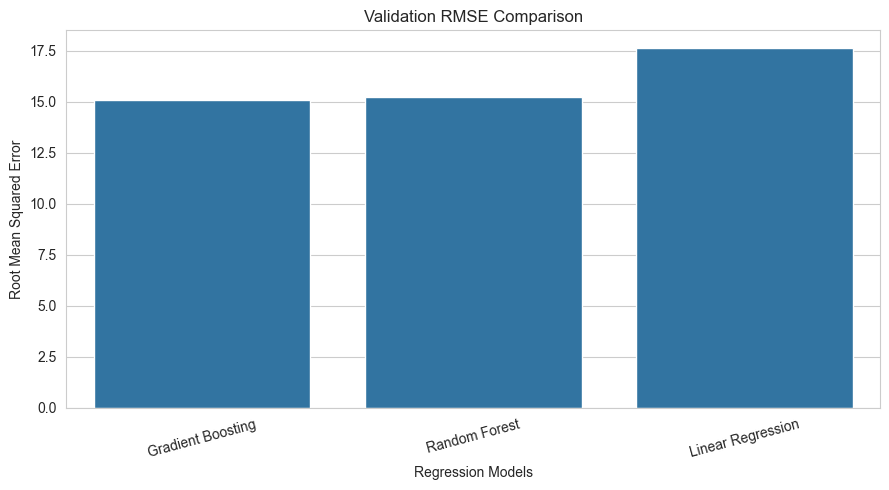

In [37]:
# Compare RMSE across all three models

plt.figure(figsize=(9, 5))

sns.barplot(
    data=validation_results,
    x='Model',
    y='RMSE'
)

plt.title("Validation RMSE Comparison")
plt.xlabel("Regression Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## 13. Best Model Selection

### 13.1 Selection Based on Validation RMSE

In [38]:
# Select the model with the lowest validation RMSE

best_model_name = validation_results.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print("Validation RMSE:",
      validation_results.iloc[0]['RMSE'])

print("Validation R2 Score:",
      validation_results.iloc[0]['R2 Score'])

Best Performing Model: Gradient Boosting
Validation RMSE: 15.107264928387643
Validation R2 Score: 0.8688484311147138


### 13.2 Best Model Performance Summary

In [39]:
# Display the selected model's performance

best_model_results = validation_results[
    validation_results['Model'] == best_model_name
]

display(best_model_results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,10.6518,228.2295,15.1073,0.8688


## 14. Final Model Training

### 14.1 Retrain the Selected Model on Complete Training Data

In [40]:
# Retrain the selected model using the complete training dataset

if best_model_name == 'Linear Regression':

    final_scaler = StandardScaler()

    X_full_scaled = final_scaler.fit_transform(X)

    best_model.fit(X_full_scaled, y)

else:

    final_scaler = None

    best_model.fit(X, y)

final_model = best_model

print("Final Model:", best_model_name)
print("Model retrained using complete training data!")
print("Training Records:", len(X))

Final Model: Gradient Boosting
Model retrained using complete training data!
Training Records: 20631


## 15. Final Testing

### 15.1 Prepare Final Test Dataset

In [41]:
# Select the final recorded cycle of each test engine

test_last = (
    test_data.sort_values('cycle')
    .groupby('engine_id')
    .tail(1)
    .sort_values('engine_id')
    .copy()
)

# Extract test features
X_test = test_last[feature_cols].copy()

# Preserve original NASA RUL values
y_test_raw = rul_data['RUL'].values

# Create capped RUL values for consistent evaluation
y_test = np.minimum(y_test_raw, RUL_CAP)

print("Test Feature Shape:", X_test.shape)
print("Original RUL Shape:", y_test_raw.shape)
print("Capped RUL Shape:", y_test.shape)

print("\nNumber of Test Engines:",
      test_last['engine_id'].nunique())

print("Maximum Original RUL:", y_test_raw.max())
print("Maximum Capped RUL:", y_test.max())

assert len(X_test) == len(y_test_raw), "Test data mismatch!"

Test Feature Shape: (100, 55)
Original RUL Shape: (100,)
Capped RUL Shape: (100,)

Number of Test Engines: 100
Maximum Original RUL: 145
Maximum Capped RUL: 125


**Observation:**

The original RUL values provided by NASA are preserved
separately from the capped RUL values.

A maximum RUL threshold of 125 cycles is applied to
maintain consistency with the training target.

Both capped and original RUL values are retained to
support comprehensive model evaluation.

### 15.2 Generate Final Predictions

In [42]:
# Generate predictions using the final trained model

if best_model_name == 'Linear Regression':

    X_test_scaled = final_scaler.transform(X_test)

    test_predictions = final_model.predict(X_test_scaled)

else:

    test_predictions = final_model.predict(X_test)

# Restrict predictions to the training RUL range
test_predictions = np.clip(
    test_predictions,
    0,
    RUL_CAP
)

print("Final test predictions generated successfully!")

print("\nFirst 10 Predictions:")
print(test_predictions[:10])

Final test predictions generated successfully!

First 10 Predictions:
[124.85636463 120.00604419  53.71002514  82.01563154  95.986537
  92.38196107 100.08453893  81.52917412 117.9159765   95.35729018]


### 15.3 Actual vs Predicted RUL

In [43]:
# Create actual vs predicted comparison

test_comparison = pd.DataFrame({
    'Engine ID': test_last['engine_id'].values,
    'Actual Capped RUL': y_test,
    'Predicted RUL': test_predictions
})

test_comparison['Prediction Error'] = (
    test_comparison['Actual Capped RUL'] -
    test_comparison['Predicted RUL']
)

display(test_comparison.head(15))

,Engine ID,Actual Capped RUL,Predicted RUL,Prediction Error
0,1,112,124.856365,-12.856365
1,2,98,120.006044,-22.006044
2,3,69,53.710025,15.289975
3,4,82,82.015632,-0.015632
4,5,91,95.986537,-4.986537
5,6,93,92.381961,0.618039
6,7,91,100.084539,-9.084539
7,8,95,81.529174,13.470826
8,9,111,117.915977,-6.915977
9,10,96,95.357290,0.642710


## 16. Final Model Performance Evaluation

### 16.1 Calculate Final Evaluation Metrics

In [44]:
# Calculate final evaluation metrics

final_mae = mean_absolute_error(y_test, test_predictions)

final_mse = mean_squared_error(y_test, test_predictions)

final_rmse = np.sqrt(final_mse)

final_r2 = r2_score(y_test, test_predictions)

# Display evaluation results
final_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Value': [final_mae, final_mse, final_rmse, final_r2]
})

print("Final Test Performance:")
display(final_results.round(4))

Final Test Performance:


,Metric,Value
0,MAE,11.9845
1,MSE,288.3114
2,RMSE,16.9797
3,R2 Score,0.8205


### 16.1.1 Evaluation Using Original Uncapped RUL

In [45]:
# Evaluate predictions against original NASA RUL values

uncapped_mae = mean_absolute_error(
    y_test_raw, test_predictions
)

uncapped_mse = mean_squared_error(
    y_test_raw, test_predictions
)

uncapped_rmse = np.sqrt(uncapped_mse)

uncapped_r2 = r2_score(
    y_test_raw, test_predictions
)

# Display uncapped evaluation results
uncapped_results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Value': [
        uncapped_mae,
        uncapped_mse,
        uncapped_rmse,
        uncapped_r2
    ]
})

print("Final Test Performance (Original Uncapped RUL):")
display(uncapped_results.round(4))

Final Test Performance (Original Uncapped RUL):


,Metric,Value
0,MAE,13.0545
1,MSE,331.5180
2,RMSE,18.2076
3,R2 Score,0.8080


**Observation:**

The model is additionally evaluated against the original
uncapped NASA RUL values.

This provides a supplementary assessment of prediction
performance without applying the 125-cycle RUL threshold
to the ground-truth test labels.

### 16.2 Actual vs Predicted RUL Visualization

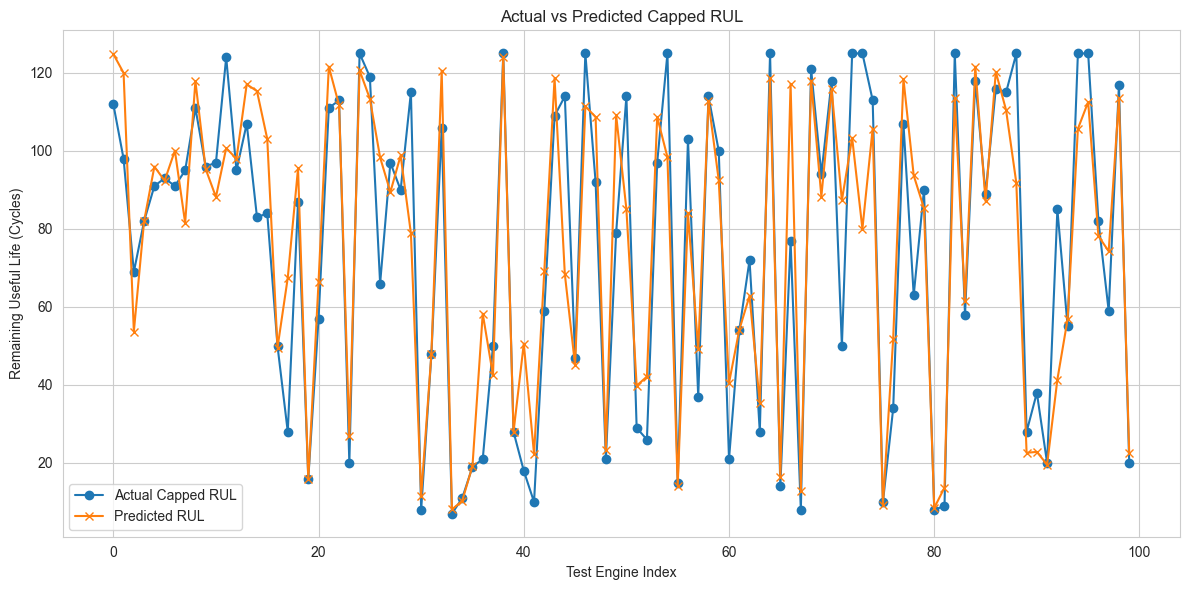

In [46]:
# Plot actual and predicted RUL values

plt.figure(figsize=(12, 6))

plt.plot(
    y_test,
    label='Actual Capped RUL',
    marker='o'
)

plt.plot(
    test_predictions,
    label='Predicted RUL',
    marker='x'
)

plt.title("Actual vs Predicted Capped RUL")
plt.xlabel("Test Engine Index")
plt.ylabel("Remaining Useful Life (Cycles)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 16.3 Actual vs Predicted RUL Scatter Plot

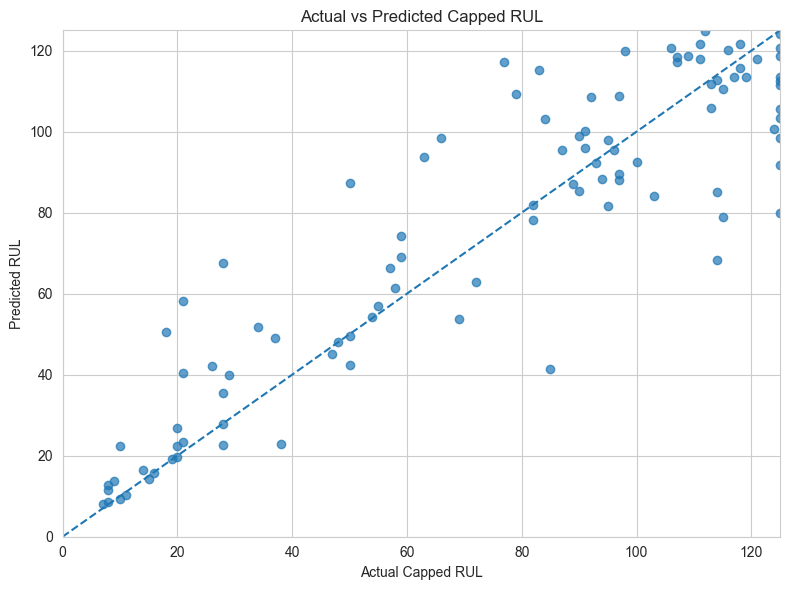

In [61]:
# Compare actual and predicted RUL using scatter plot

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

plt.plot(
    [0, RUL_CAP],
    [0, RUL_CAP],
    linestyle='--'
)

plt.title("Actual vs Predicted Capped RUL")
plt.xlabel("Actual Capped RUL")
plt.ylabel("Predicted RUL")

plt.xlim(0, RUL_CAP)
plt.ylim(0, RUL_CAP)

plt.tight_layout()
plt.show()

## 17. Feature Importance Analysis

### 17.1 Identify Important Features

In [48]:
# Extract feature importance from the selected model

importance_values = final_model.feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importance_values
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("Top 15 Important Features:")
display(feature_importance.head(15).round(4))

Top 15 Important Features:


,Feature,Importance
0,sensor_4_rolling_mean,0.3390
1,sensor_11_rolling_mean,0.1898
2,sensor_15_rolling_mean,0.1520
3,cycle,0.1324
4,sensor_2_rolling_mean,0.0500
5,sensor_3_rolling_mean,0.0389
6,sensor_9_rolling_mean,0.0330
7,sensor_21_rolling_mean,0.0151
8,sensor_17_rolling_mean,0.0128
9,sensor_14_rolling_mean,0.0098


### 17.2 Feature Importance Visualization

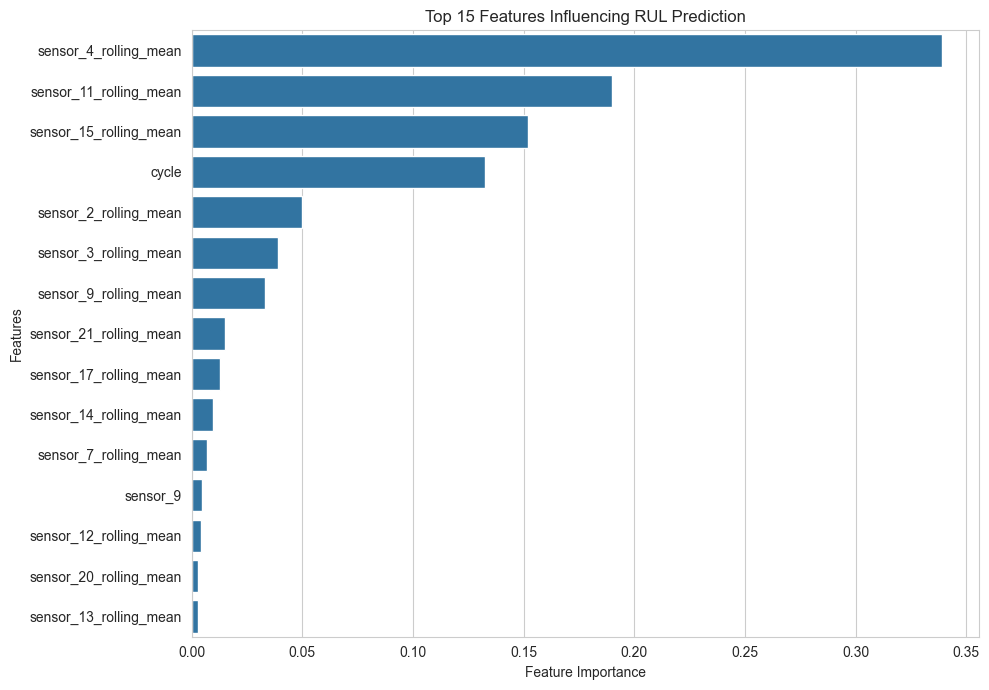

In [49]:
# Visualize the top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Features Influencing RUL Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 18. Model Saving and Export

### 18.1 Save the Trained Model

In [50]:
# Create project directories

project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

models_path = project_root / "models"
results_path = project_root / "results"

models_path.mkdir(parents=True, exist_ok=True)
results_path.mkdir(parents=True, exist_ok=True)

# Save model and its required metadata

model_bundle = {
    'model': final_model,
    'model_name': best_model_name,
    'feature_columns': feature_cols,
    'rul_cap': RUL_CAP,
    'scaler': final_scaler
}

model_file = models_path / "best_rul_model.pkl"

joblib.dump(model_bundle, model_file)

print("Model saved successfully!")
print("Model Location:", model_file)

Model saved successfully!
Model Location: c:\Users\prati\OneDrive\Desktop\aml_project\models\best_rul_model.pkl


In [51]:
# Verify the saved model file

print("Model file exists:", model_file.exists())
print("Model file size:", round(model_file.stat().st_size / 1024, 2), "KB")
print("Model file location:", model_file)

Model file exists: True
Model file size: 142.06 KB
Model file location: c:\Users\prati\OneDrive\Desktop\aml_project\models\best_rul_model.pkl


### 18.2 Save Model Evaluation Results

In [62]:
# Save validation and final evaluation results

validation_results.to_csv(
    results_path / "validation_results.csv",
    index=False
)

final_results.to_csv(
    results_path / "final_test_results.csv",
    index=False
)

feature_importance.to_csv(
    results_path / "feature_importance.csv",
    index=False
)

test_comparison.to_csv(
    results_path / "test_predictions.csv",
    index=False
)

print("All evaluation results saved successfully!")

# Save supplementary uncapped evaluation results

uncapped_results.to_csv(
    results_path / "uncapped_test_results.csv",
    index=False
)

print("Uncapped evaluation results saved successfully!")

All evaluation results saved successfully!
Uncapped evaluation results saved successfully!


In [63]:
# Verify all exported result files

expected_files = [
    "validation_results.csv",
    "final_test_results.csv",
    "feature_importance.csv",
    "test_predictions.csv"
]

for filename in expected_files:

    file_path = results_path / filename

    print(
        filename,
        "->",
        "Exists" if file_path.exists() else "Missing"
    )

validation_results.csv -> Exists
final_test_results.csv -> Exists
feature_importance.csv -> Exists
test_predictions.csv -> Exists


### 18.3 Verify Saved Files

In [64]:
# Display saved project files

print("Saved Model Files:")
for file in models_path.iterdir():
    print("-", file.name)

print("\nSaved Result Files:")
for file in results_path.iterdir():
    print("-", file.name)

Saved Model Files:
- best_rul_model.pkl

Saved Result Files:
- feature_importance.csv
- final_test_results.csv
- test_predictions.csv
- uncapped_test_results.csv
- validation_results.csv


### 18.4 Load and Verify the Saved Model

In [55]:
# Load the saved model bundle

loaded_bundle = joblib.load(model_file)

loaded_model = loaded_bundle['model']

loaded_features = loaded_bundle['feature_columns']

loaded_scaler = loaded_bundle['scaler']

print("Saved model loaded successfully!")
print("Model:", loaded_bundle['model_name'])
print("Number of features:", len(loaded_features))

Saved model loaded successfully!
Model: Gradient Boosting
Number of features: 55


### 18.5 Verify Predictions Using the Loaded Model

In [56]:
# Generate predictions using the loaded model

X_test_loaded = X_test[loaded_features]

if loaded_scaler is not None:
    X_test_loaded = loaded_scaler.transform(X_test_loaded)

loaded_predictions = loaded_model.predict(X_test_loaded)

# Compare with previously generated predictions
predictions_match = np.allclose(
    test_predictions,
    loaded_predictions
)

print("Predictions generated successfully!")
print("Number of predictions:", len(loaded_predictions))
print("Predictions match original results:", predictions_match)

Predictions generated successfully!
Number of predictions: 100
Predictions match original results: True


## 19. Conclusion

### 19.1 Project Summary
This project develops a predictive maintenance system for aircraft
engines using the NASA C-MAPSS FD001 dataset.

Three regression algorithms — Linear Regression, Random Forest
Regressor, and Gradient Boosting Regressor — were implemented
and evaluated.

Gradient Boosting Regressor achieved the lowest validation RMSE
among the three models and was selected for final testing.

The selected model was evaluated using unseen test engine data
to estimate Remaining Useful Life (RUL).

### 19.2 Project Limitations
- The implementation uses only the FD001 subset of NASA C-MAPSS.
- The model is evaluated using historical simulated engine data.
- The prediction performance may vary across different engine
  operating conditions.
- The model has not been validated using real-world aircraft
  engine operational data.

### 19.3 Future Scope
- Extend the implementation to FD002, FD003 and FD004 datasets.
- Explore advanced regression and deep learning algorithms.
- Improve feature engineering and hyperparameter tuning.
- Investigate deployment through a real-time predictive
  maintenance dashboard.